# Policy-conflict resolution at ingestion: runnable demo

Ingested Humana / CenterWell policy documents can contradict each other. This pipeline finds the conflicts **before** an advocate sees them, then either resolves them with a deterministic rules engine or sends them to a human reviewer.

**What this notebook runs:** the real pipeline code in `pcd/`, on 10 synthetic cases with known answers, using *stub* model backends. **No LLM is called and no API key is needed.** The stubs stand in for the agents so the pipeline, routing rules and eval harness can be checked on their own. Section 7 shows where a real CrewAI backend plugs in.

Everything below is plain Python, so you can re-run any cell and get the same numbers.

## 0. Setup

In [1]:
import sys, pathlib, zipfile
root = pathlib.Path.cwd()
if not (root / "pcd").exists():
    z = next(root.glob("policy_conflict_demo*.zip"), None)
    if z:
        zipfile.ZipFile(z).extractall(root); root = root / "policy_conflict_demo"
    else:
        raise SystemExit("Put policy_conflict_demo.zip next to this notebook, or run it from inside the project folder.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root / "scripts"))

import random, warnings
warnings.filterwarnings("ignore")
import pandas as pd
from pcd.evals.run_evals import load_cases, run_all
from pcd.evals.metrics import summarize
from pcd.backends.stub import OracleBackend, NoisyBackend, OracleReviewer
from pcd.pipeline import PipelineConfig, run_case
from pcd.schemas import TOPICS, Risk, Route, Status
pd.set_option("display.max_colwidth", 90, "display.width", 160)

cases = load_cases(root / "data")
print(f"project: {root}\nloaded {len(cases)} cases")

project: /home/claude/policy_conflict_demo
loaded 10 cases


## 1. The 10 test cases

Each case is two short synthetic policy documents, stored as plain text in `data/documents/*.txt`; the answer key is `data/gold.json` (and `data/gold.csv` for Excel). Gold answers (what the pipeline *should* conclude) are written by construction, not by a model, so scoring needs no judgment calls.

In [2]:
rows = []
for c in cases:
    g = c.gold.pairs[0]
    rows.append(dict(case=c.case_id, category=c.category, topic=g.claim_a_id.split(":")[1],
                     risk=g.risk.value, true_label=g.label.value, expected_route=g.route.value,
                     rule=(g.resolution.rule_fired if g.resolution else "-"),
                     final=" / ".join(s.value for s in g.final_status.values())))
pd.DataFrame(rows).set_index("case")

,category,topic,risk,true_label,expected_route,rule,final
case,,,,,,,
C01,TRUE_CONTRADICTION high-risk,specialist_referral,HIGH,TRUE_CONTRADICTION,HUMAN,R2_AUTHORITY,CERTIFIED / SCOPED
C02,TRUE_CONTRADICTION low-risk,call_summary_retention_days,LOW,TRUE_CONTRADICTION,AUTO,R2_AUTHORITY,CERTIFIED / WITHHELD
C03,TRUE_CONTRADICTION high-risk numeric,copay_primary_care,HIGH,TRUE_CONTRADICTION,HUMAN,R2_AUTHORITY,CERTIFIED / SCOPED
C04,SCOPE_DIFFERENCE state,callback_window_hours,LOW,SCOPE_DIFFERENCE,NONE,-,CERTIFIED / CERTIFIED
C05,SCOPE_DIFFERENCE plan year,appeal_filing_deadline_days,HIGH,SCOPE_DIFFERENCE,NONE,-,CERTIFIED / CERTIFIED
C06,SCOPE_DIFFERENCE plan,copay_primary_care,HIGH,SCOPE_DIFFERENCE,NONE,-,CERTIFIED / CERTIFIED
C07,OUTDATED_VERSION,document_request_turnaround_days,LOW,OUTDATED_VERSION,AUTO,R1_SUPERSEDES,WITHHELD / CERTIFIED
C08,TRUE_CONTRADICTION cross-owner,interpreter_scheduling_lead_hours,LOW,TRUE_CONTRADICTION,HUMAN,R3_SCOPE,SCOPED / CERTIFIED
C09,AMBIGUITY_TIE,call_summary_retention_days,LOW,AMBIGUITY_TIE,HUMAN,-,WITHHELD / WITHHELD


In [3]:
case = cases[0]
for d in case.documents:
    print(f"--- {d.doc_id}: {d.title}\n{d.text}\n")

--- DOC-01-A: Specialist referral rule
SYNTHETIC TEST DOCUMENT
Title: Specialist referral rule
Owner: PAYER | Type: CONTRACT_EOC | Effective: 2026-01-01 | Supersedes: none

Members may see specialists without a referral. The rule below applies to Plan NW-Gold, Florida. Questions about this rule go to the policy owner named above.
SYNTHETIC TEST DOCUMENT

--- DOC-01-B: Specialist referral rule
SYNTHETIC TEST DOCUMENT
Title: Specialist referral rule
Owner: CARE_DELIVERY | Type: CLINIC_PROCEDURE | Effective: 2026-03-01 | Supersedes: none

Members must get a referral before seeing a specialist. This section covers Florida, clinic setting. This text is a made-up example for testing the demo.
SYNTHETIC TEST DOCUMENT



## 2. Trace two cases through the pipeline (oracle backend)

The **oracle** backend returns the gold answers for every model step, so any difference from gold would be a bug in the *deterministic* code (rules, routing, status), not model noise.

- **C01**: referral rules differ between a corporate policy and a care-delivery SOP. Referrals are a benefits/access topic, so it must go to a human.
- **C02**: call-summary retention differs. Low-risk topic, clear authority ranking, so the rules engine may resolve it.

In [4]:
oracle, reviewer = OracleBackend(cases), OracleReviewer(cases)
def trace(case_id):
    c = next(x for x in cases if x.case_id == case_id)
    r = run_case(c, oracle, reviewer, PipelineConfig())
    p = r.pairs[0]
    print(f"{case_id}  [{c.category}]")
    print(f"  predicted label : {p.predicted_label.value}")
    print(f"  scope overlap   : {p.scope_overlap}   date overlap: {p.date_overlap}")
    print(f"  routing checks  : {p.checks.model_dump()}")
    print(f"  ROUTE           : {p.route.value}")
    if p.resolution:
        print(f"  resolution      : rule {p.resolution.rule_fired}, loser -> {p.resolution.loser_disposition.value}")
    print(f"  final status    : { {k.split(':')[0]: v.value for k, v in p.final_status.items()} }")
    print(f"  proposal text   : {p.proposal_text}\n")
trace("C01"); trace("C02")

C01  [TRUE_CONTRADICTION high-risk]
  predicted label : TRUE_CONTRADICTION
  scope overlap   : True   date overlap: True
  routing checks  : {'rule_applies': True, 'low_risk': False, 'no_cross_owner_tie': True}
  ROUTE           : HUMAN
  resolution      : rule R2_AUTHORITY, loser -> SCOPED
  final status    : {'DOC-01-A': 'CERTIFIED', 'DOC-01-B': 'SCOPED'}
  proposal text   : DOC-01-A:specialist_referral vs DOC-01-B:specialist_referral on specialist_referral: R2_AUTHORITY selects DOC-01-A:specialist_referral; DOC-01-B:specialist_referral is SCOPED.

C02  [TRUE_CONTRADICTION low-risk]
  predicted label : TRUE_CONTRADICTION
  scope overlap   : True   date overlap: True
  routing checks  : {'rule_applies': True, 'low_risk': True, 'no_cross_owner_tie': True}
  ROUTE           : AUTO
  resolution      : rule R2_AUTHORITY, loser -> WITHHELD
  final status    : {'DOC-02-A': 'CERTIFIED', 'DOC-02-B': 'WITHHELD'}
  proposal text   : 



## 3. Full eval on all 10 cases (oracle)

With the oracle every metric should be perfect. This is the **harness sanity check**: if this ever shows less than 100%, the deterministic code or the scoring is broken.

In [5]:
def flat(s):
    e, d, r, x = s["extraction"], s["detection"], s["routing"], s["end_to_end"]
    return {"claim recall": e["claim_recall"], "claim precision": e["claim_precision"],
            "detection accuracy": d["accuracy"], "true-contradiction recall": d["true_contradiction_recall"],
            "false-conflict rate": d["false_conflict_rate"], "routing accuracy": r["routing_accuracy"],
            "risky auto-resolved (count)": r["risky_auto_resolved"], "escalation rate": r["escalation_rate"],
            "wrong-certified rate": x["wrong_certified"]["rate"], "over-withholding rate": x["over_withholding"]["rate"],
            "model calls / case": s["cost"]["per_case"]["calls"]}
res = run_all(cases, oracle, reviewer, PipelineConfig(use_verifier=True))
pd.Series(flat(summarize(cases, res)), name="oracle").to_frame().round(3)

,oracle
claim recall,1.0
claim precision,1.0
detection accuracy,1.0
true-contradiction recall,1.0
false-conflict rate,0.0
routing accuracy,1.0
risky auto-resolved (count),0.0
escalation rate,0.4
wrong-certified rate,0.0
over-withholding rate,0.0


## 4. Add realistic mistakes: noisy backend, one seed

`NoisyBackend` corrupts each agent step at fixed rates (classify 5%, scope extraction 10%, value extraction 5%, conflict-label 15%; verifier catches 60% of bad labels). **These rates are my assumptions, not measurements.** The point is to see whether the *design* contains the damage, not to predict real model accuracy.

Same cases, seed 0, verifier on vs. off. (Seed 0 happens to draw few errors, so it looks clean; the sweep in section 5 is what shows the spread.)

In [6]:
out = {}
for name, v in [("verifier ON", True), ("verifier OFF", False)]:
    b = NoisyBackend(cases, seed=0)
    out[name] = flat(summarize(cases, run_all(cases, b, OracleReviewer(cases), PipelineConfig(use_verifier=v))))
pd.DataFrame(out).round(3)

,verifier ON,verifier OFF
claim recall,1.0,1.0
claim precision,1.0,1.0
detection accuracy,1.0,1.0
true-contradiction recall,1.0,1.0
false-conflict rate,0.0,0.0
routing accuracy,1.0,1.0
risky auto-resolved (count),0.0,0.0
escalation rate,0.4,0.4
wrong-certified rate,0.0,0.0
over-withholding rate,0.0,0.0


In [7]:
# Wilson 95% intervals on the headline safety metric, to show how little 10 cases can say.
b = NoisyBackend(cases, seed=0)
s = summarize(cases, run_all(cases, b, OracleReviewer(cases), PipelineConfig(use_verifier=True)))
for k in ("wrong_certified", "over_withholding"):
    m = s["end_to_end"][k]; lo, hi = m["ci95"]
    print(f"{k:17s} {m['k']}/{m['n']} = {m['rate']:.1%}   95% CI [{lo:.1%}, {hi:.1%}]")

wrong_certified   0/13 = 0.0%   95% CI [0.0%, 22.8%]
over_withholding  0/13 = 0.0%   95% CI [0.0%, 22.8%]


## 5. 50-seed sweep: does the routing constraint hold up?

One seed is anecdote. Here each setting is run over **50 seeds × 10 cases = 500 case-runs**. Settings stress the two weak points: the agent's conflict label (up to 40% wrong) and the extractor's *topic* (15% wrong).

Key column: **risky auto-resolved** counts pairs on a truly high-risk topic (judged by the *gold* topic) that the rules engine resolved without a human. It should be 0 in every row.

In [8]:
from seed_sweep import TopicNoisy, GOLD_TOPIC
SEEDS = range(50)
def sweep(label, verifier, topic_error=0.0, **noise):
    wk=wn=ok=on=calls=pairs=esc=risky=0
    for seed in SEEDS:
        b = TopicNoisy(cases, seed=seed, topic_error=topic_error, **noise)
        res = run_all(cases, b, OracleReviewer(cases), PipelineConfig(use_verifier=verifier))
        s = summarize(cases, res); e = s["end_to_end"]
        wk+=e["wrong_certified"]["k"]; wn+=e["wrong_certified"]["n"]
        ok+=e["over_withholding"]["k"]; on+=e["over_withholding"]["n"]; calls+=s["cost"]["calls"]
        for c in cases:
            for p in res[c.case_id].pairs:
                pairs+=1; esc+=p.route==Route.HUMAN
                risky += (p.route==Route.AUTO and TOPICS[GOLD_TOPIC[p.claim_a_id]]==Risk.HIGH)
    n=len(SEEDS)*len(cases)
    return {"setting":label,"wrong certified":wk/wn,"over-withheld":ok/on,"escalated to human":esc/max(pairs,1),
            "model calls/case":calls/n,"risky auto-resolved":risky}
sw = pd.DataFrame([
    sweep("default noise, no verifier", False),
    sweep("default noise, verifier", True),
    sweep("label error 40%, no verifier", False, detect_label_error=0.40),
    sweep("label error 40%, verifier", True, detect_label_error=0.40),
    sweep("topic error 15%, verifier", True, topic_error=0.15),
    sweep("topic 15% + label 40%, verifier", True, topic_error=0.15, detect_label_error=0.40),
]).set_index("setting")
sw.style.format({"wrong certified":"{:.1%}","over-withheld":"{:.1%}","escalated to human":"{:.1%}","model calls/case":"{:.1f}"})

,wrong certified,over-withheld,escalated to human,model calls/case,risky auto-resolved
setting,,,,,
"default noise, no verifier",0.9%,0.0%,46.0%,5.5,0
"default noise, verifier",0.6%,0.0%,51.2%,6.5,0
"label error 40%, no verifier",1.1%,0.0%,56.4%,5.6,0
"label error 40%, verifier",0.8%,0.0%,63.2%,6.6,0
"topic error 15%, verifier",13.0%,0.0%,52.1%,5.8,0
"topic 15% + label 40%, verifier",13.1%,0.0%,64.0%,5.9,0


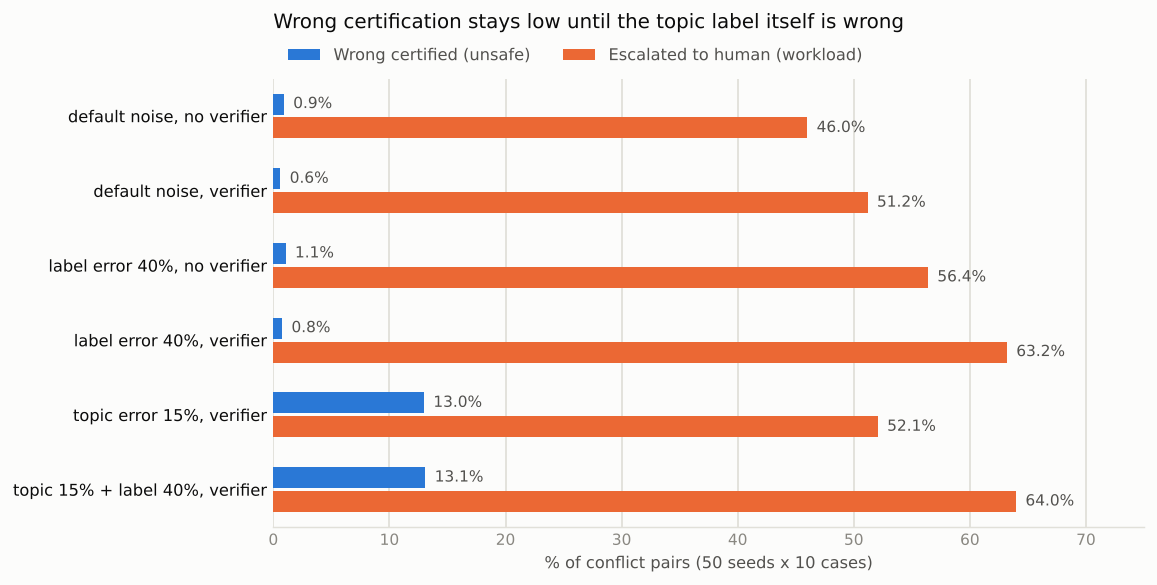

In [9]:
import matplotlib.pyplot as plt
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams["font.family"] = "DejaVu Sans"
fig, ax = plt.subplots(figsize=(9, 4.6), dpi=130, facecolor=SURF)
ax.set_facecolor(SURF)
labels = list(sw.index); y = range(len(labels)); h = 0.28
bw = ax.barh([i - h/2 - .02 for i in y], sw["wrong certified"]*100, height=h, color=BLUE, label="Wrong certified (unsafe)")
be = ax.barh([i + h/2 + .02 for i in y], sw["escalated to human"]*100, height=h, color=ORANGE, label="Escalated to human (workload)")
for bars in (bw, be):
    for r in bars:
        ax.text(r.get_width()+0.8, r.get_y()+r.get_height()/2, f"{r.get_width():.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(list(y)); ax.set_yticklabels(labels, fontsize=9, color=INK); ax.set_ylim(len(labels)-.5, -.5)
ax.set_xlim(0, 75); ax.set_xlabel("% of conflict pairs (50 seeds x 10 cases)", fontsize=9, color=INK2)
ax.tick_params(axis="x", colors=MUTED, labelsize=8.5, length=0); ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color=GRID, linewidth=1); ax.set_axisbelow(True)
for s_ in ("top","right","left"): ax.spines[s_].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title("Wrong certification stays low until the topic label itself is wrong", loc="left", fontsize=11, color=INK, pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9, labelcolor=INK2)
plt.tight_layout(); plt.show()

**How to read it.** Label noise barely moves wrong-certified (about 1%), because the routing constraint and the consistency guardrail catch bad labels by sending pairs to a human; the cost is more escalations. **Topic extraction errors are different**: wrong-certified jumps to about 13%. Next cell shows why.

## 6. The weak spot this demo found: a wrong *topic* hides a conflict

Conflict detection only compares claims on the same topic. If the extractor tags one of two conflicting claims with a different topic, the pair is never compared, so the contradiction is **never seen** and both claims are certified. The routing constraint can't help because nothing reaches it. Below: find a seed where that happens on a high-risk case.

In [10]:
found = None
for case in cases:
    g = case.gold.pairs[0]
    if g.label.value != "TRUE_CONTRADICTION" or g.risk != Risk.HIGH: continue
    for seed in range(200):
        b = TopicNoisy(cases, seed=seed, topic_error=0.15)
        r = run_case(case, b, OracleReviewer(cases), PipelineConfig(use_verifier=True))
        if not r.pairs and all(v == Status.CERTIFIED for v in r.final_status.values()):
            found = (case, seed, r); break
    if found: break
case, seed, r = found
print(f"case {case.case_id} ({case.category}), seed {seed}, topic_error=15%")
print("gold    :", case.gold.pairs[0].label.value, "-> route", case.gold.pairs[0].route.value)
print("extracted claim topics:", {c.claim_id: c.topic for c in r.claims})
print("pairs compared:", len(r.pairs))
print("final status  :", {k: v.value for k, v in r.final_status.items()})
print("\nBoth contradictory high-risk claims are CERTIFIED and no human ever saw them.")

case C01 (TRUE_CONTRADICTION high-risk), seed 0, topic_error=15%
gold    : TRUE_CONTRADICTION -> route HUMAN
extracted claim topics: {'DOC-01-A:specialist_referral': 'specialist_referral', 'DOC-01-B:specialist_referral': 'call_summary_retention_days'}
pairs compared: 0
final status  : {'DOC-01-A:specialist_referral': 'CERTIFIED', 'DOC-01-B:specialist_referral': 'CERTIFIED'}

Both contradictory high-risk claims are CERTIFIED and no human ever saw them.


**Proposed fix (not yet built):** run topic extraction twice with different prompts or models and treat any disagreement as "possible conflict" (route to human); add a gold-topic safety metric to the eval, since the current routing metric trusts the extracted topic. The 100-case version would also stress this directly.

## 7. Swap in a real CrewAI backend (optional, untested)

`CrewAIBackend` implements the same interface as the stubs, one agent task per step. It has **never been run**; five spots are marked `TODO(verify)` against the CrewAI release you install. Routing and certification stay in deterministic code, so a bad model output can at worst send a pair to a human. Uncomment to try it with your own key:

In [11]:
# !pip install crewai
# import os
# os.environ["DEMO_LLM_MODEL"] = "gpt-4o-mini"      # or any model your provider supports
# os.environ["OPENAI_API_KEY"] = "..."              # provider SDK reads its own key
# from pcd.backends.crewai_backend import CrewAIBackend
# live = CrewAIBackend()
# res = run_all(cases[:2], live, OracleReviewer(cases), PipelineConfig(use_verifier=True))
# pd.Series(flat(summarize(cases[:2], res))).round(3)

## What this does and does not show

**Shows:** the pipeline, rules engine and routing constraint work as specified; the eval harness scores them correctly (oracle = 100%); no truly high-risk pair was auto-resolved in any of the 6 × 500 noisy case-runs (but see section 6: some never got compared at all); and the harness is able to expose a real design gap (section 6).

**Does not show:**
- Real LLM accuracy. Noise rates are assumptions I chose. No model was called.
- Statistical power. 10 cases give very wide intervals; the sweep repeats the same 10 cases with different noise, so it measures robustness to noise, not generalization.
- That the CrewAI adapter works (never run).
- The reviewer is an oracle (always right); real reviewers disagree and queue up.

**Next:** fix the topic gap, grow to the planned 100 synthetic cases with a dev/test split, then run the CrewAI backend live and compare it to this stub baseline.